In [1]:
import numpy as np
import itertools

from sympy.utilities.codegen import codegen
from sage.symbolic.operators import add_vararg, mul_vararg


In [2]:
t1, t2, theta = var("t1, t2, theta")

In [3]:
Wxxx = (
    1 / 16
    + 9 * exp(-8 * t1 / 3) / (16 * (3 + 4 * theta))
    + 9 * exp(-8 * t2 / 3) / (8 * (3 + 4 * theta))
    + 27 * exp(-4 / 3 * (t1 + 2 * t2)) / (8 * (3 + 4 * theta) * (3 + 2 * theta))
)

In [4]:
Wxxy = (
    3 / 16
    + 27 * exp(-8 * t1 / 3) / (16 * (3 + 4 * theta))
    - 9 * exp(-8 * t2 / 3) / (8 * (3 + 4 * theta))
    - 27 * exp(-4 / 3 * (t1 + 2 * t2)) / (8 * (3 + 4 * theta) * (3 + 2 * theta))
)

In [5]:
Wxyx = (
    3 / 8
    - 9 * exp(-8 * t1 / 3) / (8 * (3 + 4 * theta))
    + 9 * exp(-8 * t2 / 3) / (4 * (3 + 4 * theta))
    - 27 * exp(-4 / 3 * (t1 + 2 * t2)) / (4 * (3 + 4 * theta) * (3 + 2 * theta))
)

In [6]:
Wxyz = (
    3 / 8
    - 9 * exp(-8 * t1 / 3) / (8 * (3 + 4 * theta))
    - 9 * exp(-8 * t2 / 3) / (4 * (3 + 4 * theta))
    + 27 * exp(-4 / 3 * (t1 + 2 * t2)) / (4 * (3 + 4 * theta) * (3 + 2 * theta))
)

In [7]:
Wxxx + Wxxy + Wxyx + Wxyz

1

# Redo of Julia's JC69 3-taxon species tree

In [8]:
t1, t2, tau1, tau2, theta, mu = var("t1, t2, tau1, tau2, theta, mu")

for vr in [t1, t2, tau1, tau2, theta, mu]:
    assume(vr, "real")
    assume(vr > 0)

<div>
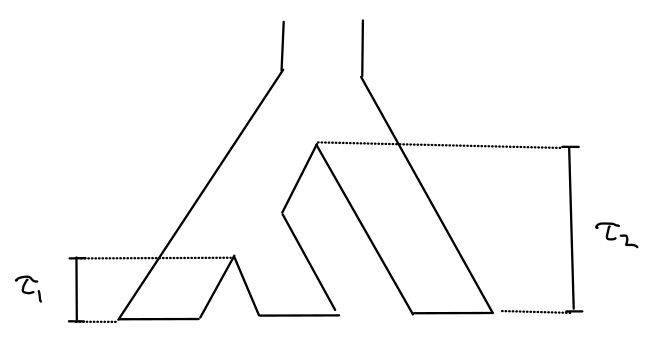
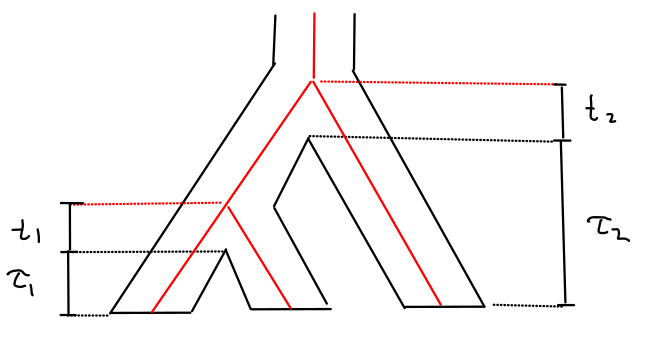
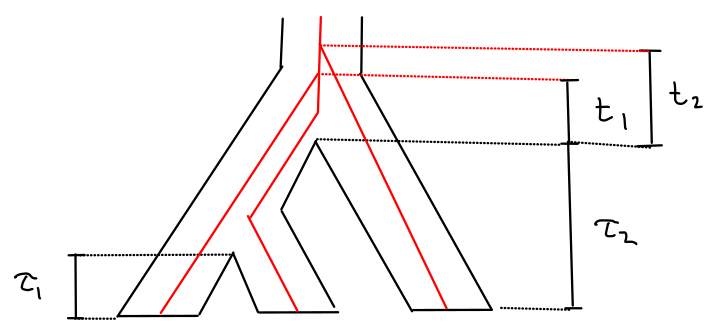
</div>

In [9]:
branch_lens = (
    (t1 + tau1, t1 + tau1, 2 * tau2 - tau1 + 2 * t2 - t1),
    (t1 + tau2, t1 + tau2, tau2 + 2 * t2 - t1),
    (t1 + tau2, t1 + tau2, tau2 + 2 * t2 - t1),
    (t1 + tau2, t1 + tau2, tau2 + 2 * t2 - t1),
)

In [10]:
Q = matrix(
    [
        [-3 * mu / 4, mu / 4, mu / 4, mu / 4],
        [mu / 4, -3 * mu / 4, mu / 4, mu / 4],
        [mu / 4, mu / 4, -3 * mu / 4, mu / 4],
        [mu / 4, mu / 4, mu / 4, -3 * mu / 4],
    ]
)

In [11]:
-sum(Q.diagonal())/4

3/4*mu

In [12]:
P(t) = exp(Q*t)

In [13]:
pretty_print(P(t))

[1/4*(e^(mu*t) + 3)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t)]
[1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) + 3)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t)]
[1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) + 3)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t)]
[1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) - 1)*e^(-mu*t) 1/4*(e^(mu*t) + 3)*e^(-mu*t)]

In [ ]:
# for l1, l2, l3 in branch_lens:
#     print(
#         P(
#     )

In [ ]:
densities = [
    (np.einsum("ni,nj,nk->ijk", P(l1), P(l2), P(l3)) / 4) for l1, l2, l3 in branch_lens
]

In [ ]:
f1 = (4 / theta ^ 2) * exp((-2 / theta) * (t1 + t2))

pretty_print(f1)

In [ ]:
f2 = (
    (4 / theta ^ 2)
    * exp((-2 / theta) * (tau2 - tau1))
    * exp((-2 / theta) * (t2 - t1))
    * exp((-6 / theta) * t1)
)

pretty_print(f2)

In [ ]:
part1 = np.array(
    [
        [
            [
                integrate(
                    integrate(densities[0][i, j, k] * f1, (t2, 0, oo)),
                    (t1, 0, tau2 - tau1),
                )
                for k in range(4)
            ]
            for j in range(4)
        ]
        for i in range(4)
    ]
)

In [ ]:
part2 = np.array(
    [
        [
            [
                integrate(
                    integrate(
                        (
                            densities[1][i, j, k]
                            + densities[2][i, k, j]
                            + densities[3][j, k, i]
                        )
                        * f2,
                        (t1, 0, t2),
                    ),
                    (t2, 0, oo),
                )
                for k in range(4)
            ]
            for j in range(4)
        ]
        for i in range(4)
    ]
)

In [ ]:
S = part1 + part2

In [ ]:
sum(
    [S[i, j, k] for i, j, k in itertools.product(range(4), repeat=3)]
).simplify_full()

In [ ]:
S[0, 0, 0].simplify_full().variables()

In [ ]:
S[0,0,0].simplify_full()

In [ ]:
(S[0,0,0]-S[1,1,1]).simplify_full(), (S[0,0,0]-S[2,2,2]).simplify_full(), (S[0,0,0]-S[3,3,3]).simplify_full()

In [ ]:
for i, j, k in itertools.product(range(4), repeat=3):
    if i == j and i != k:
        print( (S[0,0,1] - S[i,j,k]).simplify_full() )

In [ ]:
for i, j, k in itertools.product(range(4), repeat=3):
    if i == k and i != j:
        print( (S[0,1,0] - S[i,j,k]).simplify_full() )

In [ ]:
for i, j, k in itertools.combinations(range(4), 3):
    print( (S[0,1,2] - S[i,j,k]).simplify_full() )

In [ ]:
# alpha_i = exp(mu*tau_i)
alpha1, alpha2 = var('alpha1, alpha2')
assume(alpha1 > 0)
assume(alpha2 > 0)

# beta = 1/(mu*theta)
beta = var('beta')
assume(beta > 0)

### to_lse

In [202]:
def lse_print(self, *args):
    if len(args) > 1:
        return f"log_sum_exp(std::array<double,{len(args)}>{{" + ",".join([str(term) for term in args]) + "})"
    else:
        return str(args[0])

log_sum_exp = function('log_sum_exp', print_func=lse_print)
log_diff_exp = function('log_diff_exp', nargs=2)
log1p = function('log1p')
symb_exp = function('exp')

def to_lse(exp):
    if exp == log(-e^tau1 + e^tau2):
        return tau2 + log1p(-symb_exp(tau1-tau2))
    try:
        op = exp.operator()
        try:
            if op.name() == 'log':
                terms = exp.operands()[0]
                if terms == beta:
                    return exp
                elif terms == 1+2*beta:
                    return log1p(2*beta)
                elif terms == 1+3*beta:
                    return log1p(3*beta)
                try:
                    sub_op = terms.operator()
                    if sub_op == add_vararg:
                        pos_terms = [ op for op in terms.operands() if op({v:1 for v in op.variables()}) >= 0]
                        neg_terms = [ op for op in terms.operands() if op({v:1 for v in op.variables()}) < 0]
                        if len(neg_terms) > 0:
                            return log_diff_exp(
                                log_sum_exp(*[log(t).expand_log() for t in pos_terms]),
                                log_sum_exp(*[log(-t).expand_log() for t in neg_terms]),
                            )
                        else:
                            log_sub_terms = [log(t).expand_log() for t in terms.operands()]
                            return log_sum_exp(*log_sub_terms)
                    else:
                        return exp
                except:
                    return exp
        except:
            pass
        if op == add_vararg:
            return sum([to_lse(sub_exp) for sub_exp in exp.operands()])
        elif op == mul_vararg:
            return mul_vararg(*[to_lse(sub_exp) for sub_exp in exp.operands()])
        else:
            return exp
    except:
        return exp


In [203]:
def indent(s,n=1):
    return ("  "*n) + s.replace("\n","\n" + ("  "*n))

### Sxxx

In [ ]:
pretty_print(S[0,0,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor())

In [ ]:
pretty_print(S[0,0,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().numerator().factor())

In [ ]:
log_denom = log(S[0,0,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().denominator().factor())(alpha1=exp(tau1), alpha2=exp(tau2)).expand_log()

log_denom

In [ ]:
numerator = (S[0,0,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().numerator().factor())

pretty_print(numerator)
print(numerator)

In [ ]:
to_lse(log(numerator(alpha1=exp(tau1), alpha2=exp(tau2)))) - log_denom

In [ ]:
base = (S[0,0,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().numerator().factor())

coeffs = []

for i,j in itertools.product(range(3)[::-1], repeat=2):
    top = base.coefficient(alpha1^i*alpha2^j).factor()
    base = (base - alpha1^i*alpha2^j*top).factor()
    if top != 0:
        coeffs.append( log(alpha1^i*alpha2^j*top)(alpha1=exp(tau1), alpha2=exp(tau2)).expand_log() )

print( f"log_sum_exp(\n  std::array<double,{len(coeffs)}>" + "{" + ",\n\t".join([str(c) for c in coeffs]) + "})\n-(" + str(log_denom) + ")")

### Sxxy

In [ ]:
pretty_print(S[0,0,1](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor())

In [ ]:
log_denom = log(S[0,0,1](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().denominator().factor())(alpha1=exp(tau1), alpha2=exp(tau2)).expand_log()

log_denom

In [ ]:
numerator = (S[0,0,1](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().numerator().factor())

pretty_print(numerator)
print(numerator)

In [ ]:
to_lse(log(numerator(alpha1=exp(tau1), alpha2=exp(tau2)))) - log_denom

### Sxyx

In [ ]:
pretty_print(S[0,1,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor())

In [ ]:
denominator = S[0,1,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().denominator()

pretty_print(denominator)

In [ ]:
log_denominator = (log(denominator)(alpha1=exp(tau1), alpha2=exp(tau2))).expand_log()

pretty_print(log_denominator)

In [ ]:
numerator = (S[0,1,0](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor() * denominator).factor()
pretty_print(numerator)
numerator

In [ ]:
to_lse(log(numerator(alpha1=exp(tau1), alpha2=exp(tau2)))) - log_denom

### Sxyz

In [ ]:
pretty_print(S[0,1,2](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor())

In [ ]:
denominator = S[0,1,2](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor().denominator()

pretty_print(denominator)

In [ ]:
log_denominator = (log(denominator)(alpha1=exp(tau1), alpha2=exp(tau2))).expand_log()

pretty_print(log_denominator)

In [ ]:
numerator = (S[0,1,2](tau1=log(alpha1)/(mu), tau2=log(alpha2)/(mu))(mu=1/(beta*theta)).simplify_full().factor() * denominator).factor()
pretty_print(numerator)
numerator

In [ ]:
to_lse(log(numerator(alpha1=exp(tau1), alpha2=exp(tau2)))) - log_denom

# Alternate $t_i$

<div>
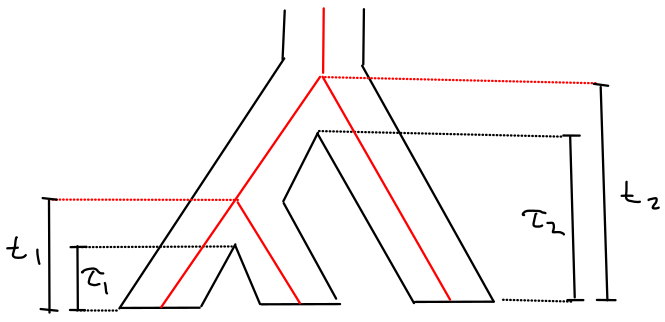
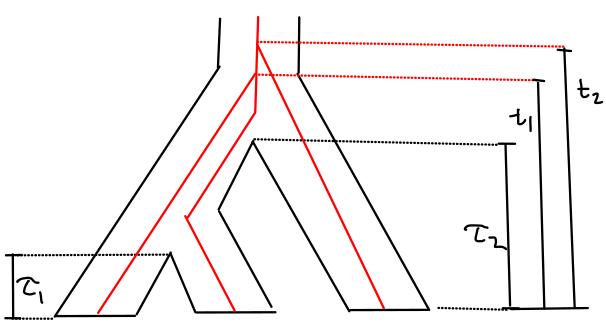
</div>


In [ ]:
branch_lens = (
    (t1, t1, t2 - t1),
    (t1, t1, t2 - t1),
    (t1, t1, t2 - t1),
    (t1, t1, t2 - t1),
)

In [ ]:
P(t) = exp(Q*t)

pretty_print(P(t))

In [ ]:
densities = [
    (np.einsum("ni,nj,nk->ijk", P(l1), P(l2), P(l3)) / 4) for l1, l2, l3 in branch_lens
]

In [ ]:
f1 = (2 / theta) * exp((-2 / theta) * (t1 - tau1)) * (2 / theta) * exp((-2 / theta) * (t2 - tau2))

pretty_print(f1)

In [ ]:
part1 = np.array(
    [
        [
            [
                integrate(
                    integrate(densities[0][i, j, k] * f1, (t2, tau2, oo)),
                    (t1, tau1, tau2),
                )
                for k in range(4)
            ]
            for j in range(4)
        ]
        for i in range(4)
    ]
)

In [ ]:
f2 = (
    exp((-2 / theta) * (tau2 - tau1))
    * (6 / theta) * exp((-6 / theta) * (t1 - tau2))
    * (2 / theta) * exp((-2 / theta) * (t2 - t1))
) / 3

pretty_print(f2)

In [ ]:
part2 = np.array(
    [
        [
            [
                integrate(
                    integrate(
                        (
                            densities[1][i, j, k]
                            + densities[2][i, k, j]
                            + densities[3][j, k, i]
                        )
                        * f2,
                        (t1, tau2, t2),
                    ),
                    (t2, tau2, oo),
                )
                for k in range(4)
            ]
            for j in range(4)
        ]
        for i in range(4)
    ]
)

In [ ]:
S = part1 + part2

In [ ]:
sum(
    [S[i, j, k] for i, j, k in itertools.product(range(4), repeat=3)]
).simplify_full()

# Scratch

In [61]:
s, d  = var('s, d')
s1, s2, s3 = var('s1,s2,s3')

In [62]:
densities = np.einsum("ni,nj,nk->ijk", P(s1), P(s2), P(s3)) / 4

In [63]:
densities.shape

(4, 4, 4)

In [64]:
Pxxx = 0
Pxxy = 0
Pxyx = 0
Pyxx = 0
Pxyz = 0
for i,j,k in itertools.product(range(4),repeat=3):
    if i == j == k:
        Pxxx += densities[i,j,k]
    elif i == j and j != k:
        Pxxy += densities[i,j,k]
    elif i == k and i != j:
        Pxyx += densities[i,j,k]
    elif j == k and i != j:
        Pyxx += densities[i,j,k]
    elif i != j and i != k and j != k:
        Pxyz += densities[i,j,k]
    else:
        assert False

In [132]:
sp_xxx = (
    integrate(
        integrate(
            (
                # T0 congruent
                integrate(
                    integrate(
                        Pxxx(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau1)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau1, tau2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T1 deep congruent
                integrate(
                    integrate(
                        Pxxx(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T2 deep discordant: ((a,c),b) 
                integrate(
                    integrate(
                        Pxxx(s1=t1,s2=2*t2-t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T3 deep discordant ((b,c),a)
                integrate(
                    integrate(
                        Pxxx(s1=2*t2-t1,s2=t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2)) * (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                )
            ) * exp( -2/theta * tau1 ) * exp( -2/theta *( tau2-tau1)) * 2/theta^2,
            (tau1, 0, tau2)
        ),
        (tau2, 0, oo)
    )
)
pretty_print(sp_xxx)

1/32*(54*mu^7*theta^9 + 414*mu^6*theta^8 + 1407*mu^5*theta^7 + 2927*mu^4*theta^6 + 4804*mu^3*theta^5 + 5796*mu^2*theta^4 + 3872*mu*theta^3 + 1024*theta^2)/((27*mu^7*theta^7 + 207*mu^6*theta^6 + 663*mu^5*theta^5 + 1153*mu^4*theta^4 + 1178*mu^3*theta^3 + 708*mu^2*theta^2 + 232*mu*theta + 32)*theta^2)

In [133]:
sp_xxy = (
    integrate(
        integrate(
            (
                # T0 congruent
                integrate(
                    integrate(
                        Pxxy(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau1)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau1, tau2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T1 deep congruent
                integrate(
                    integrate(
                        Pxxy(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T2 deep discordant: ((a,c),b) 
                integrate(
                    integrate(
                        Pxxy(s1=t1,s2=2*t2-t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T3 deep discordant ((b,c),a)
                integrate(
                    integrate(
                        Pxxy(s1=2*t2-t1,s2=t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2)) * (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                )
            ) * exp( -2/theta * tau1 ) * exp( -2/theta *( tau2-tau1)) * 2/theta^2,
            (tau1, 0, tau2)
        ),
        (tau2, 0, oo)
    )
)
pretty_print(sp_xxy)

3/32*(54*mu^6*theta^8 + 360*mu^5*theta^7 + 1047*mu^4*theta^6 + 1664*mu^3*theta^5 + 1412*mu^2*theta^4 + 480*mu*theta^3)/((27*mu^6*theta^6 + 180*mu^5*theta^5 + 483*mu^4*theta^4 + 670*mu^3*theta^3 + 508*mu^2*theta^2 + 200*mu*theta + 32)*theta^2)

In [134]:
sp_xyx = (
    integrate(
        integrate(
            (
                # T0 congruent
                integrate(
                    integrate(
                        Pxyx(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau1)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau1, tau2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T1 deep congruent
                integrate(
                    integrate(
                        Pxyx(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T2 deep discordant: ((a,c),b) 
                integrate(
                    integrate(
                        Pxyx(s1=t1,s2=2*t2-t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T3 deep discordant ((b,c),a)
                integrate(
                    integrate(
                        Pxyx(s1=2*t2-t1,s2=t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2)) * (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                )
            ) * exp( -2/theta * tau1 ) * exp( -2/theta *( tau2-tau1)) * 2/theta^2,
            (tau1, 0, tau2)
        ),
        (tau2, 0, oo)
    )
)
pretty_print(sp_xyx)

3/32*(54*mu^7*theta^9 + 414*mu^6*theta^8 + 1299*mu^5*theta^7 + 2207*mu^4*theta^6 + 2260*mu^3*theta^5 + 1348*mu^2*theta^4 + 352*mu*theta^3)/((27*mu^7*theta^7 + 207*mu^6*theta^6 + 663*mu^5*theta^5 + 1153*mu^4*theta^4 + 1178*mu^3*theta^3 + 708*mu^2*theta^2 + 232*mu*theta + 32)*theta^2)

In [135]:
sp_yxx = (
    integrate(
        integrate(
            (
                # T0 congruent
                integrate(
                    integrate(
                        Pyxx(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau1)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau1, tau2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T1 deep congruent
                integrate(
                    integrate(
                        Pyxx(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T2 deep discordant: ((a,c),b) 
                integrate(
                    integrate(
                        Pyxx(s1=t1,s2=2*t2-t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T3 deep discordant ((b,c),a)
                integrate(
                    integrate(
                        Pyxx(s1=2*t2-t1,s2=t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2)) * (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                )
            ) * exp( -2/theta * tau1 ) * exp( -2/theta *( tau2-tau1)) * 2/theta^2,
            (tau1, 0, tau2)
        ),
        (tau2, 0, oo)
    )
)
pretty_print(sp_yxx)

3/32*(54*mu^7*theta^9 + 414*mu^6*theta^8 + 1299*mu^5*theta^7 + 2207*mu^4*theta^6 + 2260*mu^3*theta^5 + 1348*mu^2*theta^4 + 352*mu*theta^3)/((27*mu^7*theta^7 + 207*mu^6*theta^6 + 663*mu^5*theta^5 + 1153*mu^4*theta^4 + 1178*mu^3*theta^3 + 708*mu^2*theta^2 + 232*mu*theta + 32)*theta^2)

In [136]:
sp_xyz = (
    integrate(
        integrate(
            (
                # T0 congruent
                integrate(
                    integrate(
                        Pxyz(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau1)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau1, tau2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T1 deep congruent
                integrate(
                    integrate(
                        Pxyz(s1=t1,s2=t1,s3=2*t2-t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T2 deep discordant: ((a,c),b) 
                integrate(
                    integrate(
                        Pxyz(s1=t1,s2=2*t2-t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2))* (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                ) +
                # T3 deep discordant ((b,c),a)
                integrate(
                    integrate(
                        Pxyz(s1=2*t2-t1,s2=t1,s3=t1) * exp( -2/theta*(t1 - tau2)) * exp( -2/theta * (t2-tau2)) * (2/theta)^2,
                        (t1, tau2, t2)
                    ),
                    (t2, tau2, oo)
                )
            ) * exp( -2/theta * tau1 ) * exp( -2/theta *( tau2-tau1)) * 2/theta^2,
            (tau1, 0, tau2)
        ),
        (tau2, 0, oo)
    )
)
pretty_print(sp_xyz)

3/16*(54*mu^7*theta^9 + 414*mu^6*theta^8 + 1299*mu^5*theta^7 + 2099*mu^4*theta^6 + 1684*mu^3*theta^5 + 516*mu^2*theta^4)/((27*mu^7*theta^7 + 207*mu^6*theta^6 + 663*mu^5*theta^5 + 1153*mu^4*theta^4 + 1178*mu^3*theta^3 + 708*mu^2*theta^2 + 232*mu*theta + 32)*theta^2)

In [137]:
(sp_xxx + sp_xxy + sp_xyx + sp_yxx + sp_xyz).simplify_full()

1

In [138]:
pretty_print(sp_xyz(mu=1).factor())

3/16*(54*theta^5 + 414*theta^4 + 1299*theta^3 + 2099*theta^2 + 1684*theta + 516)*theta^2/((3*theta + 4)*(3*theta + 2)^2*(theta + 2)*(theta + 1)^3)

In [139]:
sp_xxx(mu=1, theta=0.5)

0.288231807874665

In [140]:
sp_xxy(mu=1, theta=0.5)

0.217323747680891

In [141]:
sp_xyx(mu=1, theta=0.5)

0.161768192125335

In [142]:
sp_yxx(mu=1, theta=0.5)

0.161768192125335

In [143]:
sp_xyz(mu=1, theta=0.5)

0.170908060193774

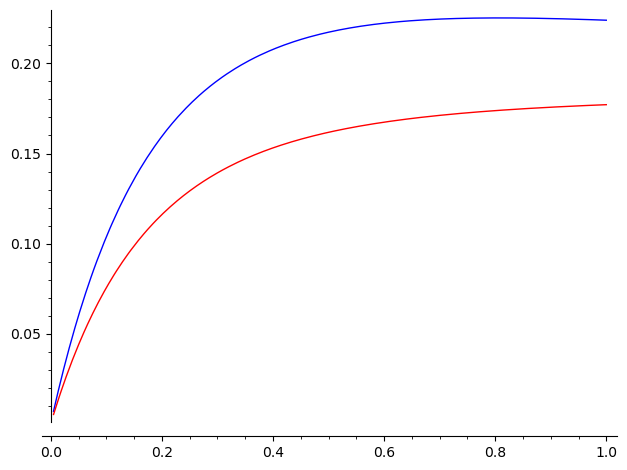

In [144]:
plot( sp_xxy(mu=1), (theta, 0, 1)) + plot( sp_xyx(mu=1), (theta, 0, 1), color='red')

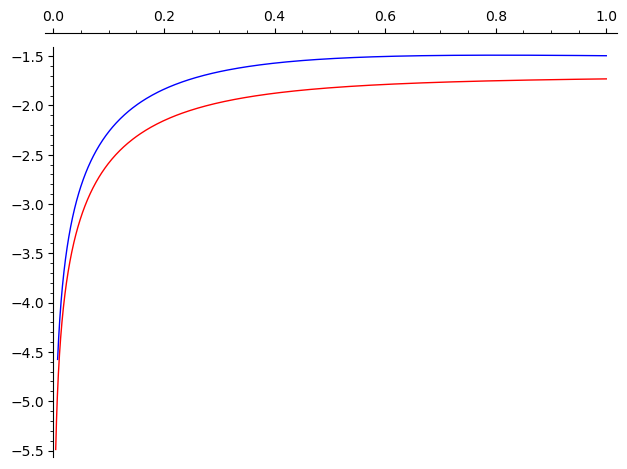

In [145]:
plot( log(sp_xxy(mu=1)), (theta, 0, 1)) + plot( log(sp_xyx(mu=1)), (theta, 0, 1), color='red')

In [196]:
pretty_print(
    sp_xxx.factor()
)
pretty_print(
    sp_xxy.factor()
)
pretty_print(
    sp_xyx.factor()
)
pretty_print(
    sp_yxx.factor()
)
pretty_print(
    sp_xyz.factor()
)

1/32*(54*mu^7*theta^7 + 414*mu^6*theta^6 + 1407*mu^5*theta^5 + 2927*mu^4*theta^4 + 4804*mu^3*theta^3 + 5796*mu^2*theta^2 + 3872*mu*theta + 1024)/((3*mu*theta + 4)*(3*mu*theta + 2)^2*(mu*theta + 2)*(mu*theta + 1)^3)

3/32*(54*mu^5*theta^5 + 360*mu^4*theta^4 + 1047*mu^3*theta^3 + 1664*mu^2*theta^2 + 1412*mu*theta + 480)*mu*theta/((3*mu*theta + 4)*(3*mu*theta + 2)^2*(mu*theta + 2)*(mu*theta + 1)^2)

3/32*(54*mu^6*theta^6 + 414*mu^5*theta^5 + 1299*mu^4*theta^4 + 2207*mu^3*theta^3 + 2260*mu^2*theta^2 + 1348*mu*theta + 352)*mu*theta/((3*mu*theta + 4)*(3*mu*theta + 2)^2*(mu*theta + 2)*(mu*theta + 1)^3)

3/32*(54*mu^6*theta^6 + 414*mu^5*theta^5 + 1299*mu^4*theta^4 + 2207*mu^3*theta^3 + 2260*mu^2*theta^2 + 1348*mu*theta + 352)*mu*theta/((3*mu*theta + 4)*(3*mu*theta + 2)^2*(mu*theta + 2)*(mu*theta + 1)^3)

3/16*(54*mu^5*theta^5 + 414*mu^4*theta^4 + 1299*mu^3*theta^3 + 2099*mu^2*theta^2 + 1684*mu*theta + 516)*mu^2*theta^2/((3*mu*theta + 4)*(3*mu*theta + 2)^2*(mu*theta + 2)*(mu*theta + 1)^3)

In [201]:
log(sp_xxx(mu=x/theta).factor()).expand_log()

-5*log(2) + log(54*x^7 + 414*x^6 + 1407*x^5 + 2927*x^4 + 4804*x^3 + 5796*x^2 + 3872*x + 1024) - log(3*x + 4) - 2*log(3*x + 2) - log(x + 2) - 3*log(x + 1)

In [206]:
log(sp_xxy(mu=x/theta).factor()).expand_log()

log(3/32) + log(54*x^5 + 360*x^4 + 1047*x^3 + 1664*x^2 + 1412*x + 480) - log(3*x + 4) - 2*log(3*x + 2) - log(x + 2) - 2*log(x + 1) + log(x)

In [207]:
log(sp_xyx(mu=x/theta).factor()).expand_log()

log(3/32) + log(54*x^6 + 414*x^5 + 1299*x^4 + 2207*x^3 + 2260*x^2 + 1348*x + 352) - log(3*x + 4) - 2*log(3*x + 2) - log(x + 2) - 3*log(x + 1) + log(x)

In [208]:
log(sp_yxx(mu=x/theta).factor()).expand_log()

log(3/32) + log(54*x^6 + 414*x^5 + 1299*x^4 + 2207*x^3 + 2260*x^2 + 1348*x + 352) - log(3*x + 4) - 2*log(3*x + 2) - log(x + 2) - 3*log(x + 1) + log(x)

In [209]:
log(sp_xyz(mu=x/theta).factor()).expand_log()

log(3/16) + log(54*x^5 + 414*x^4 + 1299*x^3 + 2099*x^2 + 1684*x + 516) - log(3*x + 4) - 2*log(3*x + 2) - log(x + 2) - 3*log(x + 1) + 2*log(x)